# Ejercicios resueltos de la UD1: correlaciones entre variables

Este cuaderno acompaña a los apuntes de la UD1 y reúne los **ejercicios resueltos sobre correlaciones entre variables** que he planteado para practicar la unidad, organizados en **niveles de dificultad**, uno por apartado. Cada enunciado incluye los **datos de partida y su configuración** (semillas, tamaños de muestra, parámetros), de modo que el trabajo se centra en el análisis. Más adelante, preparar los datos formará parte del propio ejercicio.

Os recomiendo intentar cada ejercicio antes de leer la solución, aunque solo lleguéis a la mitad: atascarse un rato y comparar después enseña mucho más que leer la respuesta directamente. Y si el nivel avanzado se os resiste, es normal; está pensado para que cueste un poco.

Las celdas de solución continúan la de los datos, de modo que hay que ejecutarlas en orden.

Bibliotecas: NumPy, pandas, SciPy, Matplotlib, seaborn y scikit-learn (entorno `ml-modelos`).


## Apartado I.

### Ejercicio 1. Media, varianza y el parámetro ddof

A partir de los años de nacimiento de un grupo de compositoras de música clásica, **calcular la media, la varianza poblacional, la varianza muestral y la desviación típica**. Comprobar la diferencia entre el comportamiento por defecto de NumPy y el de pandas, y **razonar a qué se debe**.

Compositoras: [Hildegard von Bingen](https://es.wikipedia.org/wiki/Hildegarda_de_Bingen) (1098), [Barbara Strozzi](https://es.wikipedia.org/wiki/Barbara_Strozzi) (1619), [Marianna Martines](https://es.wikipedia.org/wiki/Marianne_von_Martinez) (1744), [Fanny Mendelssohn](https://es.wikipedia.org/wiki/Fanny_Mendelssohn) (1805), [Clara Schumann](https://es.wikipedia.org/wiki/Clara_Schumann) (1819), [Ethel Smyth](https://es.wikipedia.org/wiki/Ethel_Smyth) (1858) y [Lili Boulanger](https://es.wikipedia.org/wiki/Lili_Boulanger) (1893).

**Ayuda:** [`np.var`](https://numpy.org/doc/stable/reference/generated/numpy.var.html), [`np.std`](https://numpy.org/doc/stable/reference/generated/numpy.std.html) y [`Series.var`](https://pandas.pydata.org/docs/reference/api/pandas.Series.var.html), con su parámetro `ddof`. Repaso en el apartado 2.

**Datos de partida.**

In [1]:
import numpy as np
import pandas as pd

# Años de nacimiento de siete compositoras, de Hildegard von Bingen a Lili Boulanger
nacimiento = np.array([1098, 1619, 1744, 1805, 1819, 1858, 1893], dtype=float)

#### Solución del ejercicio 1

In [2]:
media = nacimiento.mean()
var_poblacional = np.var(nacimiento)          # NumPy: ddof=0 por defecto
var_muestral = np.var(nacimiento, ddof=1)     # divide entre n - 1
desv_muestral = np.std(nacimiento, ddof=1)

print(f"Media: {media:.1f}")
print(f"Varianza poblacional (NumPy por defecto): {var_poblacional:.1f}")
print(f"Varianza muestral (ddof=1):               {var_muestral:.1f}")
print(f"Desviación típica muestral:               {desv_muestral:.1f}")

# pandas usa ddof=1 por defecto, de modo que coincide con la versión muestral
serie = pd.Series(nacimiento)
print(f"\nVarianza con pandas (ddof=1 por defecto): {serie.var():.1f}")
print(f"Varianza con pandas forzando ddof=0:      {serie.var(ddof=0):.1f}")
n = len(nacimiento)
print(f"Cociente entre ambas varianzas:           {var_muestral / var_poblacional:.4f}")
print(f"Factor n / (n - 1):                       {n / (n - 1):.4f}")

Media: 1690.9
Varianza poblacional (NumPy por defecto): 65387.8
Varianza muestral (ddof=1):               76285.8
Desviación típica muestral:               276.2

Varianza con pandas (ddof=1 por defecto): 76285.8
Varianza con pandas forzando ddof=0:      65387.8
Cociente entre ambas varianzas:           1.1667
Factor n / (n - 1):                       1.1667


**Explicación.** NumPy divide entre $n$ (**varianza poblacional**) salvo que se indique `ddof=1`, mientras que pandas divide entre $n-1$ (**varianza muestral**) por defecto. Las dos varianzas difieren exactamente en el factor $n/(n-1) = 7/6$, una diferencia apreciable con solo siete datos y despreciable con muestras grandes. Conviene **fijar `ddof` de forma explícita** cuando se combinan resultados de ambas bibliotecas para que los números cuadren.

La desviación típica, de unos 276 años, está inflada por un único dato: Hildegard von Bingen nació más de cinco siglos antes que las demás. Es un primer aviso de lo que se verá con Pearson en el apartado 4.4: las medidas basadas en la media son muy sensibles a los valores extremos.

### Ejercicio 2. Covarianza y signo de la relación

Para una muestra de películas de cine clásico con su duración (minutos) y su número de reseñas, **calcular la matriz de covarianzas con pandas**. **Razonar el signo de la covarianza** entre ambas variables y explicar **por qué su valor numérico resulta poco interpretable**.

Las películas son *Metrópolis*, de [Fritz Lang](https://es.wikipedia.org/wiki/Fritz_Lang); *Casablanca*, de [Michael Curtiz](https://es.wikipedia.org/wiki/Michael_Curtiz); *Los siete samuráis*, de [Akira Kurosawa](https://es.wikipedia.org/wiki/Akira_Kurosawa); *Cuentos de Tokio*, de [Yasujirō Ozu](https://es.wikipedia.org/wiki/Yasujir%C5%8D_Ozu); y *El séptimo sello* y *Persona*, de [Ingmar Bergman](https://es.wikipedia.org/wiki/Ingmar_Bergman). El número de reseñas es una cifra ilustrativa.

**Ayuda:** [`DataFrame.cov`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.cov.html) y [`DataFrame.corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html). Repaso en el apartado 3.

**Datos de partida.**

In [3]:
import pandas as pd

peliculas = pd.DataFrame({
    "titulo": ["Metrópolis", "Casablanca", "Los siete samuráis",
               "Cuentos de Tokio", "El séptimo sello", "Persona"],
    "duracion":   [153, 102, 207, 136, 96, 85],      # minutos
    "n_resenhas": [180, 590, 220, 175, 200, 140],    # cifras ilustrativas
})

#### Solución del ejercicio 2

In [4]:
print(peliculas[["duracion", "n_resenhas"]].cov().round(1))

# Misma relación con la duración en horas: la covarianza cambia, la correlación no
peliculas["duracion_h"] = peliculas["duracion"] / 60
cov_min = peliculas["duracion"].cov(peliculas["n_resenhas"])
cov_h = peliculas["duracion_h"].cov(peliculas["n_resenhas"])
r_min = peliculas["duracion"].corr(peliculas["n_resenhas"])
r_h = peliculas["duracion_h"].corr(peliculas["n_resenhas"])
print(f"\nCovarianza con la duración en minutos: {cov_min:.1f}")
print(f"Covarianza con la duración en horas:   {cov_h:.1f}")
print(f"Correlación en minutos: {r_min:.3f}   en horas: {r_h:.3f}")

            duracion  n_resenhas
duracion      2091.8     -1447.8
n_resenhas   -1447.8     28324.2

Covarianza con la duración en minutos: -1447.8
Covarianza con la duración en horas:   -24.1
Correlación en minutos: -0.188   en horas: -0.188


**Comentario.** En la diagonal aparecen las varianzas de cada variable y fuera de ella la covarianza. **El signo es negativo** (-1447,8): las películas más largas de la muestra no son las más reseñadas, sobre todo porque *Casablanca*, con una duración inferior a la media, acumula muchas más reseñas que el resto.

El signo indica el sentido de la relación, pero **su magnitud mezcla unidades** (minutos por número de reseñas). Basta con expresar la duración en horas para que la covarianza se divida entre 60 (pasa a -24,1), aunque la relación sea exactamente la misma. Por eso no permite comparar la intensidad con la de otras parejas de variables. Para eso hace falta el **coeficiente de correlación, que es adimensional** y no cambia con las unidades: vale -0,19 en los dos casos, una relación débil. Con seis películas, en cualquier caso, el valor obtenido no describe nada general sobre el cine clásico.

### Ejercicio 3. Coeficiente de Pearson por tres vías

Generar 100 puntos de una relación lineal con ruido y **calcular el coeficiente de Pearson con NumPy, con pandas y con SciPy**. **Comprobar que las tres vías coinciden e interpretar el p-valor** que devuelve SciPy.

**Ayuda:** [`np.corrcoef`](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html), [`Series.corr`](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html) y [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html). Repaso en el apartado 4.1.

**Datos de partida.** La configuración fija la semilla, el tamaño de la muestra, la pendiente y la desviación típica del ruido.

In [5]:
import numpy as np

rng = np.random.default_rng(2026)     # semilla fija: resultados reproducibles
n = 100
x = rng.uniform(0, 10, n)             # x uniforme entre 0 y 10
y = 2.0 * x + rng.normal(0, 2, n)     # recta de pendiente 2 más ruido gaussiano (desviación 2)

#### Solución del ejercicio 3

In [6]:
import pandas as pd
from scipy import stats

r_numpy = np.corrcoef(x, y)[0, 1]
r_pandas = pd.Series(x).corr(pd.Series(y))
r_scipy, p_valor = stats.pearsonr(x, y)

print(f"Pearson (NumPy):  {r_numpy:.4f}")
print(f"Pearson (pandas): {r_pandas:.4f}")
print(f"Pearson (SciPy):  {r_scipy:.4f}")
print(f"p-valor: {p_valor:.2e}")

Pearson (NumPy):  0.9068
Pearson (pandas): 0.9068
Pearson (SciPy):  0.9068
p-valor: 1.50e-38


**Comentario.** Los tres métodos devuelven el mismo coeficiente. `np.corrcoef` devuelve la matriz de correlaciones completa (de ahí el `[0, 1]`), pandas trabaja con series o DataFrames y SciPy añade el p-valor.

El **p-valor contrasta la hipótesis nula de correlación poblacional cero**: un valor tan pequeño indica que una correlación como la observada sería muy improbable si las variables fueran realmente incorreladas. **El coeficiente mide la intensidad de la relación y el p-valor, su fiabilidad estadística**: con muestras grandes, correlaciones débiles pueden ser muy significativas, de modo que conviene leer siempre los dos.

### Ejercicio 4. Matriz de correlación y pareja más relacionada

Con un conjunto de películas de cine clásico (año, duración, valoración y número de reseñas), **calcular la matriz de correlación de Pearson y localizar, mediante código, la pareja de variables con mayor correlación** en valor absoluto, excluyendo la diagonal.

**Ayuda:** [`DataFrame.corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) (con `numeric_only=True`, porque hay una columna de texto), [`np.eye`](https://numpy.org/doc/stable/reference/generated/numpy.eye.html), [`DataFrame.where`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.where.html), [`DataFrame.stack`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.stack.html) y [`Series.idxmax`](https://pandas.pydata.org/docs/reference/api/pandas.Series.idxmax.html). Repaso en el apartado 4.2.

**Datos de partida.** Ocho películas, con la valoración media aproximada de IMDb y un número de reseñas ilustrativo.

In [7]:
import numpy as np
import pandas as pd

peliculas = pd.DataFrame({
    "titulo": ["Metrópolis", "Casablanca", "Cuentos de Tokio", "Los siete samuráis",
               "El séptimo sello", "Psicosis", "Ocho y medio", "Persona"],
    "anho":       [1927, 1942, 1953, 1954, 1957, 1960, 1963, 1966],
    "duracion":   [153, 102, 136, 207, 96, 109, 138, 85],
    "valoracion": [8.3, 8.5, 8.2, 8.6, 8.2, 8.5, 8.1, 8.1],
    "n_resenhas": [180, 590, 175, 220, 200, 680, 150, 140],
})

#### Solución del ejercicio 4

In [8]:
corr = peliculas.corr(numeric_only=True)     # se excluye la columna de títulos
print(corr.round(2))

# Pareja con mayor correlación absoluta, ignorando la diagonal
corr_sin_diag = corr.where(~np.eye(len(corr), dtype=bool))
pareja = corr_sin_diag.abs().stack().idxmax()
valor = corr.loc[pareja]
print(f"\nPareja más correlacionada: {pareja[0]} y {pareja[1]} (r = {valor:.2f})")

            anho  duracion  valoracion  n_resenhas
anho        1.00     -0.29       -0.31       -0.08
duracion   -0.29      1.00        0.44       -0.28
valoracion -0.31      0.44        1.00        0.66
n_resenhas -0.08     -0.28        0.66        1.00

Pareja más correlacionada: valoracion y n_resenhas (r = 0.66)


**Comentario.** `np.eye` crea una matriz identidad booleana que, negada, marca todo salvo la diagonal; con `where` la diagonal pasa a `NaN`. El método `stack()` aplana después la matriz a una serie indexada por parejas, lo que permite localizar el máximo con `idxmax()`. Como la matriz es simétrica, cada pareja aparece dos veces, pero el máximo es el mismo. La pareja más correlacionada es la valoración y el número de reseñas (0,66).

Desde pandas 2.0, `corr()` ya no descarta en silencio las columnas de texto: sin `numeric_only=True` se produce un error. Con solo ocho filas los coeficientes son muy inestables: el ejercicio ilustra el procedimiento, no un resultado sobre el cine clásico.

### Ejercicio 5. Pearson frente a Spearman en una relación ordenada

Sea una variable $x$ con valores de 1 a 10 y una variable $y = x^3$. La relación es **perfectamente monótona pero no lineal**. **Calcular Pearson y Spearman** y explicar por qué Spearman devuelve exactamente 1 y Pearson, algo menos.

**Ayuda:** [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html), [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html) y [`Series.rank`](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html). Repaso en el apartado 5.

**Datos de partida.**

In [9]:
import numpy as np

x = np.arange(1, 11, dtype=float)    # 1, 2, ..., 10
y = x ** 3

#### Solución del ejercicio 5

In [10]:
import pandas as pd
from scipy import stats

r_pearson = stats.pearsonr(x, y).statistic
rho_spearman = stats.spearmanr(x, y).statistic
print(f"Pearson:  {r_pearson:.4f}")
print(f"Spearman: {rho_spearman:.4f}")

# Spearman es Pearson aplicado a los rangos
rangos = pd.DataFrame({"x": x, "y": y}).rank()
print(f"Pearson sobre los rangos: {rangos['x'].corr(rangos['y']):.4f}")

Pearson:  0.9284
Spearman: 1.0000
Pearson sobre los rangos: 1.0000


**Comentario.** **Spearman trabaja con rangos**: como $y$ crece siempre que crece $x$, los rangos de ambas variables son idénticos (1, 2, ..., 10) y $\rho$ vale exactamente 1. La última línea lo comprueba: el coeficiente de Spearman no es más que el de Pearson calculado sobre los rangos. **Pearson mide la linealidad** de la nube de puntos, que aquí se curva, por lo que devuelve un valor alto pero inferior a 1.

## Apartado II.

### Ejercicio 6. Mapa de calor con máscara triangular

A partir de los datos de siete compositoras (año de nacimiento, año de fallecimiento, años de vida, número de obras y número de obras impresas en vida con su nombre), **representar su matriz de correlación como mapa de calor**, mostrando **solo el triángulo inferior** para evitar la información duplicada.

**Ayuda:** [`seaborn.heatmap`](https://seaborn.pydata.org/generated/seaborn.heatmap.html) (parámetro `mask`), [`np.triu`](https://numpy.org/doc/stable/reference/generated/numpy.triu.html) y [`np.ones_like`](https://numpy.org/doc/stable/reference/generated/numpy.ones_like.html). Repaso en el apartado 4.2 y en el resumen de funciones.

**Datos de partida.** Son los mismos datos del ejercicio propuesto 1, con sus cifras aproximadas. Hildegard von Bingen tiene un valor ausente en `en_vida`, porque en el siglo XII no existía la imprenta.

In [11]:
import numpy as np
import pandas as pd

compositoras = pd.DataFrame({
    "nacimiento":    [1098, 1619, 1744, 1805, 1819, 1858, 1893],
    "fallecimiento": [1179, 1677, 1812, 1847, 1896, 1944, 1918],
    "obras":         [78, 125, 200, 460, 66, 90, 50],
    "en_vida":       [np.nan, 115, 3, 32, 25, 60, 8],   # obras impresas en vida
}, index=["Hildegard von Bingen", "Barbara Strozzi", "Marianna Martines",
          "Fanny Mendelssohn", "Clara Schumann", "Ethel Smyth", "Lili Boulanger"])
compositoras["anhos_vida"] = compositoras["fallecimiento"] - compositoras["nacimiento"]

#### Solución del ejercicio 6

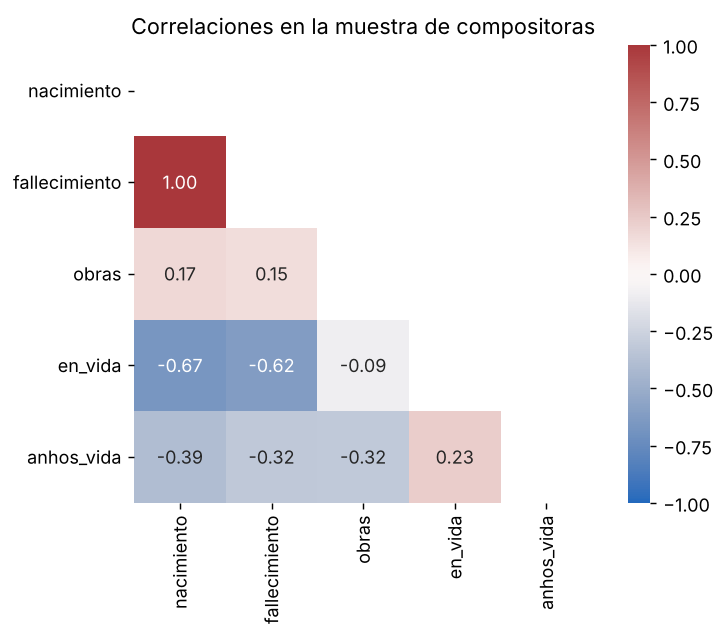

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = compositoras.corr()      # por parejas: con en_vida se usan seis filas

mascara = np.triu(np.ones_like(corr, dtype=bool))   # oculta el triángulo superior y la diagonal
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlaciones en la muestra de compositoras")
plt.tight_layout()
plt.show()

**Comentario.** La matriz de correlación es simétrica y su diagonal vale siempre 1, así que el triángulo superior repite el inferior. La máscara creada con `np.triu` (que incluye la diagonal) evita esa redundancia visual. La paleta divergente (`vlag`) con el rango fijado entre -1 y 1 hace que el color blanco corresponda siempre a la ausencia de correlación lineal.

Hay que leer el mapa con dos cautelas. La primera, que algunas relaciones son **redundancias por construcción**: la correlación de 1,00 entre nacimiento y fallecimiento no descubre nada (las vidas duran décadas y las fechas abarcan ocho siglos), y los años de vida son una columna derivada de esas dos. La segunda, que el número de obras impresas en vida arrastra un **sesgo histórico**: parte de la obra de Fanny Mendelssohn se publicó con el nombre de su hermano [Felix](https://es.wikipedia.org/wiki/Felix_Mendelssohn), como se analiza en el ejercicio propuesto 1. Con siete filas, en cualquier caso, ningún coeficiente es fiable.

### Ejercicio 7. Efecto de un valor atípico sobre Pearson y Spearman

Generar 50 puntos de dos variables independientes (correlación esperada próxima a cero). **Añadir después un único valor atípico extremo y comparar cómo cambian Pearson y Spearman.** Repetir con 1, 3 y 5 atípicos y **representar gráficamente la evolución** de ambos coeficientes.

**Ayuda:** [`Generator.normal`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html), [`np.append`](https://numpy.org/doc/stable/reference/generated/numpy.append.html), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html). Repaso en el apartado 4.4.

**Datos de partida.** Son los mismos 50 puntos del apartado 4.4 (semilla 0). Los atípicos se colocan en el punto (30, 30).

In [13]:
import numpy as np

rng = np.random.default_rng(0)
x = rng.normal(5, 1, 50)
y = rng.normal(5, 1, 50)          # independiente de x

atipico = (30, 30)                # posición de los valores atípicos
n_atipicos = [0, 1, 3, 5]         # casos que se comparan

#### Solución del ejercicio 7

0 atípicos -> Pearson -0.108, Spearman -0.055
1 atípicos -> Pearson +0.922, Spearman +0.006
3 atípicos -> Pearson +0.972, Spearman +0.114
5 atípicos -> Pearson +0.982, Spearman +0.207


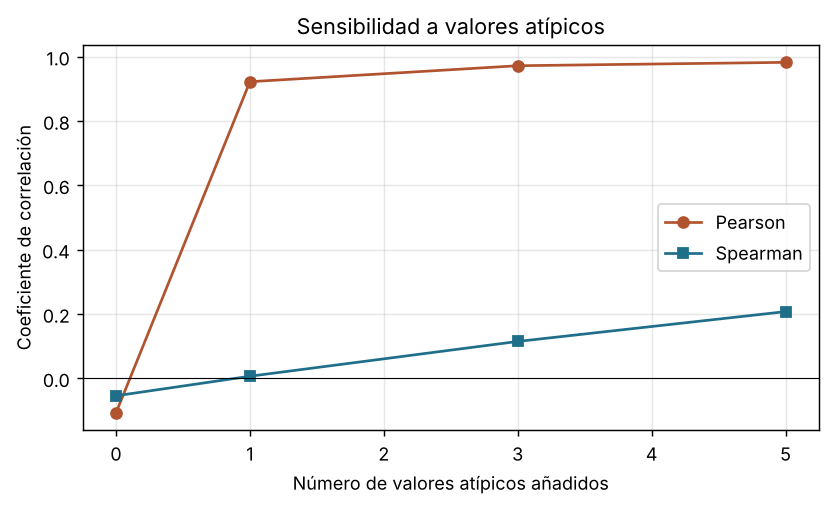

In [14]:
from scipy import stats
import matplotlib.pyplot as plt

pearson, spearman = [], []
for k in n_atipicos:
    xa = np.append(x, [atipico[0]] * k)
    ya = np.append(y, [atipico[1]] * k)
    pearson.append(stats.pearsonr(xa, ya).statistic)
    spearman.append(stats.spearmanr(xa, ya).statistic)
    print(f"{k} atípicos -> Pearson {pearson[-1]:+.3f}, Spearman {spearman[-1]:+.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(n_atipicos, pearson, "o-", color="#b1532f", label="Pearson")
ax.plot(n_atipicos, spearman, "s-", color="#1f6f8b", label="Spearman")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Número de valores atípicos añadidos")
ax.set_ylabel("Coeficiente de correlación")
ax.set_title("Sensibilidad a valores atípicos")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Comentario.** Con datos sin relación, **un solo punto extremo dispara Pearson** hacia valores cercanos a 1, porque se apoya en medias y desviaciones, muy sensibles a los extremos. **Spearman, basado en rangos, apenas se inmuta** con el primero: un valor extremo, por extremo que sea, solo ocupa el último rango en cada variable. Al acumular atípicos, Spearman también sube, porque cada uno aporta concordancia en los rangos más altos de las dos variables (el ejercicio propuesto 3 lo estudia con detalle). De ahí la importancia de la **detección de atípicos**, que se trabaja en el módulo 5109, antes de analizar correlaciones.

### Ejercicio 8. Linealizar una relación mediante transformación

El periodo de un [péndulo simple](https://es.wikipedia.org/wiki/P%C3%A9ndulo_simple) sigue la ley $T = 2\pi\sqrt{L/g}$. Con datos de longitud $L$ y periodo $T$ medidos con un poco de ruido, **comprobar que Spearman supera a Pearson** y, aplicando la transformación que sugiere la física, **encontrar una transformación de las variables que haga que Pearson se aproxime a 1**.

**Ayuda:** [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html). Repaso en el apartado 6 y en el paso 4 del flujo de trabajo.

**Datos de partida.** Sesenta longitudes entre 0,1 y 4 metros y un error de medida del periodo de 0,02 segundos.

In [15]:
import numpy as np

rng = np.random.default_rng(2026)
g = 9.81                                    # aceleración de la gravedad (m/s²)
L = np.linspace(0.1, 4, 60)                 # longitudes (m)
T = 2 * np.pi * np.sqrt(L / g) + rng.normal(0, 0.02, L.size)   # periodos medidos (s)

#### Solución del ejercicio 8

Pearson(L, T):       0.9839
Spearman(L, T):      0.9998
Pearson(L, T**2):    0.9997
Pearson(sqrt(L), T): 0.9998


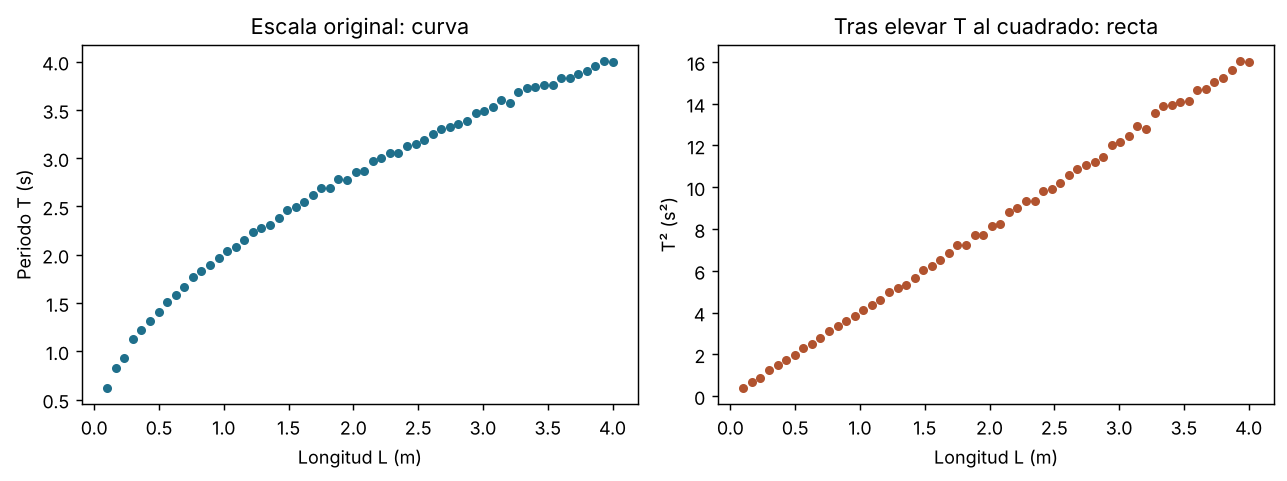

In [16]:
from scipy import stats
import matplotlib.pyplot as plt

print(f"Pearson(L, T):       {stats.pearsonr(L, T).statistic:.4f}")
print(f"Spearman(L, T):      {stats.spearmanr(L, T).statistic:.4f}")

# La física dice que T² es proporcional a L: basta con elevar T al cuadrado
print(f"Pearson(L, T**2):    {stats.pearsonr(L, T**2).statistic:.4f}")
# Alternativa equivalente: T es proporcional a la raíz de L
print(f"Pearson(sqrt(L), T): {stats.pearsonr(np.sqrt(L), T).statistic:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(L, T, s=16, color="#1f6f8b")
axes[0].set(xlabel="Longitud L (m)", ylabel="Periodo T (s)", title="Escala original: curva")
axes[1].scatter(L, T**2, s=16, color="#b1532f")
axes[1].set(xlabel="Longitud L (m)", ylabel="T² (s²)", title="Tras elevar T al cuadrado: recta")
plt.tight_layout()
plt.show()

**Comentario.** Spearman supera a Pearson porque la relación es **monótona pero curva**. Al elevar $T$ al cuadrado (o tomar la raíz de $L$) la relación se vuelve lineal y Pearson sube hasta casi 1: $T^2 = (4\pi^2/g)\,L$ es una recta que pasa por el origen. **Proponer la transformación que endereza la curva** es la base del ajuste de datos experimentales, y permite reutilizar modelos lineales sobre relaciones no lineales, como se hará en la regresión de la UD7.

### Ejercicio 9. Independencia de variables categóricas con chi-cuadrado

Con un pequeño catálogo de obras de pensadores y pensadoras del siglo XX, clasificado por tradición (analítica, continental o política) y ámbito temático, **construir la tabla de contingencia, aplicar el contraste chi-cuadrado y calcular la V de Cramér**. **Comentar la limitación de las frecuencias esperadas mínimas**.

Las autorías son [Bertrand Russell](https://es.wikipedia.org/wiki/Bertrand_Russell), [Ludwig Wittgenstein](https://es.wikipedia.org/wiki/Ludwig_Wittgenstein), [Jean-Paul Sartre](https://es.wikipedia.org/wiki/Jean-Paul_Sartre), [Simone de Beauvoir](https://es.wikipedia.org/wiki/Simone_de_Beauvoir), [Hannah Arendt](https://es.wikipedia.org/wiki/Hannah_Arendt), [Angela Davis](https://es.wikipedia.org/wiki/Angela_Davis), [Karl Popper](https://es.wikipedia.org/wiki/Karl_Popper), [Noam Chomsky](https://es.wikipedia.org/wiki/Noam_Chomsky), [Simone Weil](https://es.wikipedia.org/wiki/Simone_Weil) y [Elizabeth Anscombe](https://es.wikipedia.org/wiki/Elizabeth_Anscombe), alumna y traductora de Wittgenstein (no confundir con el estadístico Francis Anscombe, el del cuarteto del ejercicio 11).

**Ayuda:** [`pd.crosstab`](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html), [`scipy.stats.chi2_contingency`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html) y [`scipy.stats.contingency.association`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html). Repaso en el apartado 7.

**Datos de partida.** La clasificación es simplificada: una sola tradición y un solo ámbito por autoría.

In [17]:
import pandas as pd

obras = pd.DataFrame({
    "autoria":   ["Russell", "Wittgenstein", "Sartre", "Beauvoir", "Arendt",
                  "Davis", "Popper", "Chomsky", "Weil", "Anscombe"],
    "tradicion": ["analítica", "analítica", "continental", "continental", "política",
                  "política", "analítica", "analítica", "continental", "analítica"],
    "ambito":    ["lógica", "lenguaje", "existencialismo", "feminismo", "totalitarismo",
                  "racismo", "epistemología", "lenguaje", "ética", "ética"],
})

#### Solución del ejercicio 9

In [18]:
import numpy as np
from scipy import stats

tabla = pd.crosstab(obras["tradicion"], obras["ambito"])
print(tabla.to_string() + "\n")

resultado = stats.chi2_contingency(tabla)
n = tabla.to_numpy().sum()
k = min(tabla.shape) - 1
v_cramer = np.sqrt(resultado.statistic / (n * k))

print(f"Chi-cuadrado = {resultado.statistic:.2f}")
print(f"p-valor = {resultado.pvalue:.3f}")
print(f"Grados de libertad = {resultado.dof}")
print(f"V de Cramér (fórmula) = {v_cramer:.3f}")
print(f"V de Cramér (SciPy)   = {stats.contingency.association(tabla, method='cramer'):.3f}")
print(f"Frecuencia esperada máxima: {resultado.expected_freq.max():.2f}")

ambito       epistemología  existencialismo  feminismo  lenguaje  lógica  racismo  totalitarismo  ética
tradicion                                                                                              
analítica                1                0          0         2       1        0              0      1
continental              0                1          1         0       0        0              0      1
política                 0                0          0         0       0        1              1      0

Chi-cuadrado = 17.33
p-valor = 0.239
Grados de libertad = 14
V de Cramér (fórmula) = 0.931
V de Cramér (SciPy)   = 0.931
Frecuencia esperada máxima: 1.00


**Comentario.** El chi-cuadrado indica si hay dependencia y **la V de Cramér la cuantifica entre 0 y 1**; la fórmula y la función de SciPy dan el mismo valor. El resultado es llamativo: una V de Cramér altísima (0,93) junto a un p-valor (0,24) que no permite rechazar la independencia. La contradicción es solo aparente. Con diez observaciones repartidas en 24 casillas, **todas las frecuencias esperadas están muy por debajo de 5** (la mayor vale 1), de modo que la aproximación chi-cuadrado no es válida y el p-valor no es fiable. Y con ocho ámbitos para diez obras, casi cada ámbito tiene una sola obra y, por tanto, una sola tradición: cualquier clasificación así parecerá perfectamente asociada. El resultado debe leerse únicamente como ilustración del procedimiento. El apartado 7 explica cómo agrupar categorías para cumplir la condición, y el ejercicio propuesto 5 lo practica.

### Ejercicio 10. Detección de redundancia entre variables (multicolinealidad)

**Escribir una función que, dada una tabla de datos y un umbral, devuelva todas las parejas de variables cuya correlación absoluta supere ese umbral.** Aplicarla a un conjunto en el que una variable es deliberadamente redundante (un presupuesto expresado a la vez en euros y en dólares) para **detectar la redundancia**.

**Ayuda:** [`DataFrame.corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html), [`Generator.uniform`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.uniform.html) y el recorrido del triángulo superior de una matriz. Repaso en el apartado 1 (multicolinealidad).

**Datos de partida.** Cuarenta películas ficticias. El tipo de cambio es fijo, de modo que la columna en dólares es una transformación lineal exacta de la columna en euros.

In [19]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
n = 40
presupuesto_eur = rng.uniform(0.5, 5, n)              # millones de euros
datos = pd.DataFrame({
    "presupuesto_eur": presupuesto_eur,
    "presupuesto_usd": presupuesto_eur * 1.08,        # redundante: misma información
    "duracion": rng.uniform(80, 200, n),              # minutos
    "valoracion": rng.uniform(5, 9, n),
})

#### Solución del ejercicio 10

In [20]:
def parejas_redundantes(df, umbral=0.9):
    """Devuelve las parejas de columnas con correlación absoluta mayor que el umbral."""
    corr = df.corr(numeric_only=True).abs()
    columnas = corr.columns
    resultado = []
    for i in range(len(columnas)):
        for j in range(i + 1, len(columnas)):     # solo el triángulo superior
            valor = corr.iloc[i, j]
            if valor > umbral:
                resultado.append((columnas[i], columnas[j], round(float(valor), 3)))
    return resultado


print(parejas_redundantes(datos, umbral=0.95))
print(datos.corr().round(2))

[('presupuesto_eur', 'presupuesto_usd', 1.0)]
                 presupuesto_eur  presupuesto_usd  duracion  valoracion
presupuesto_eur             1.00             1.00      0.12        0.05
presupuesto_usd             1.00             1.00      0.12        0.05
duracion                    0.12             0.12      1.00        0.07
valoracion                  0.05             0.05      0.07        1.00


**Comentario.** La función recorre **solo el triángulo superior** de la matriz para no repetir parejas. Detecta que las dos columnas de presupuesto están **perfectamente correlacionadas** ($r = 1$): aportan la misma información y una de las dos sobra. El resto de correlaciones son próximas a cero, como corresponde a variables generadas de forma independiente. **Eliminar variables redundantes** mejora la estabilidad de los modelos lineales y anticipa la selección de variables de la UD3 y la reducción de la dimensión de las UD4 y UD5.

## Apartado III.

### Ejercicio 11. Reproducir el cuarteto de Anscombe

Con los cuatro conjuntos del [cuarteto de Anscombe](https://es.wikipedia.org/wiki/Cuarteto_de_Anscombe), publicado por el estadístico [Francis Anscombe](https://en.wikipedia.org/wiki/Frank_Anscombe) en 1973, **comprobar numéricamente que comparten media de x, media de y, coeficiente de Pearson y recta de regresión casi idénticos**, y **representar los cuatro diagramas de dispersión con su recta ajustada** para evidenciar que las formas son completamente distintas.

**Ayuda:** [`np.polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [`plt.subplots`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html). Repaso en el apartado 4.3.

**Datos de partida.** Los once pares de cada conjunto, tal como los publicó Anscombe. Los tres primeros comparten los valores de x.

In [21]:
import numpy as np

x123 = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], dtype=float)
y1 = np.array([8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68])
y2 = np.array([9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74])
y3 = np.array([7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73])
x4 = np.array([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], dtype=float)
y4 = np.array([6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89])

conjuntos = [(x123, y1, "I"), (x123, y2, "II"), (x123, y3, "III"), (x4, y4, "IV")]

#### Solución del ejercicio 11

Conjunto   I: media x = 9.00, media y = 7.50, r = 0.816, recta y = 0.50x + 3.00
Conjunto  II: media x = 9.00, media y = 7.50, r = 0.816, recta y = 0.50x + 3.00
Conjunto III: media x = 9.00, media y = 7.50, r = 0.816, recta y = 0.50x + 3.00
Conjunto  IV: media x = 9.00, media y = 7.50, r = 0.817, recta y = 0.50x + 3.00


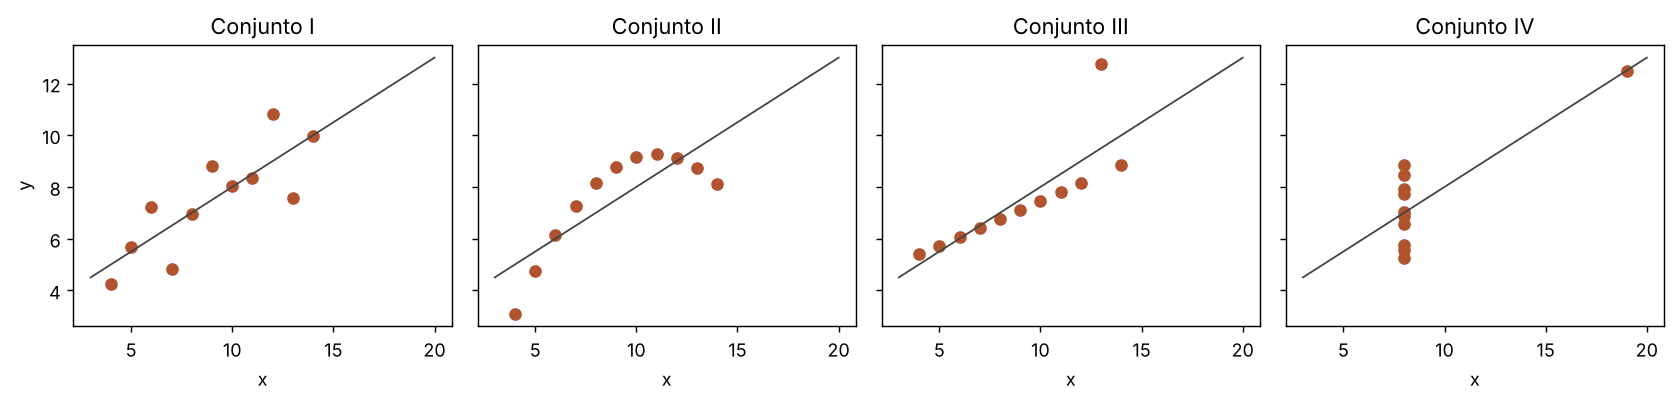

In [22]:
from scipy import stats
import matplotlib.pyplot as plt

for xx, yy, etiqueta in conjuntos:
    r = stats.pearsonr(xx, yy).statistic
    pendiente, ordenada = np.polyfit(xx, yy, 1)
    print(f"Conjunto {etiqueta:>3}: media x = {xx.mean():.2f}, media y = {yy.mean():.2f}, "
          f"r = {r:.3f}, recta y = {pendiente:.2f}x + {ordenada:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (xx, yy, etiqueta) in zip(axes, conjuntos):
    pendiente, ordenada = np.polyfit(xx, yy, 1)
    rejilla = np.linspace(3, 20, 10)
    ax.scatter(xx, yy, color="#b1532f")
    ax.plot(rejilla, pendiente * rejilla + ordenada, color="#444444", lw=1)
    ax.set_title(f"Conjunto {etiqueta}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

**Comentario.** Los cuatro conjuntos comparten prácticamente todos los estadísticos resumen, pero **su estructura es radicalmente distinta**: una relación lineal con ruido, una curva, una recta perfecta desviada por un atípico y una columna vertical con un punto aislado que fabrica por sí solo la correlación. La lección es que **ningún coeficiente sustituye a la inspección gráfica de los datos**, principio que enlaza con el RA3 y la UD6.

### Ejercicio 12. Información mutua frente a Pearson en relaciones no monótonas

**Comparar el comportamiento de Pearson, Spearman y la [información mutua](https://es.wikipedia.org/wiki/Informaci%C3%B3n_mutua)** sobre tres relaciones: una lineal, una parabólica (no monótona) y una sinusoidal. **Explicar por qué la información mutua detecta dependencias que los coeficientes de correlación no capturan.**

**Ayuda:** [`mutual_info_regression`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_regression.html) de scikit-learn, que espera una matriz de dos dimensiones (`x.reshape(-1, 1)`). Repaso en el apartado 6.

**Datos de partida.** Ochocientos valores de x uniformes entre -3 y 3 y tres variables y construidas a partir de ellos con ruido gaussiano.

In [23]:
import numpy as np

rng = np.random.default_rng(2026)
x = rng.uniform(-3, 3, 800)

relaciones = {
    "lineal":     2 * x + rng.normal(0, 0.5, x.size),
    "parabólica": x ** 2 + rng.normal(0, 0.5, x.size),
    "sinusoidal": np.sin(2 * x) + rng.normal(0, 0.2, x.size),
}

#### Solución del ejercicio 12

relación       Pearson  Spearman  Inf. mutua
lineal           0.990     0.990       1.900
parabólica       0.064     0.097       1.472
sinusoidal      -0.391    -0.377       1.176


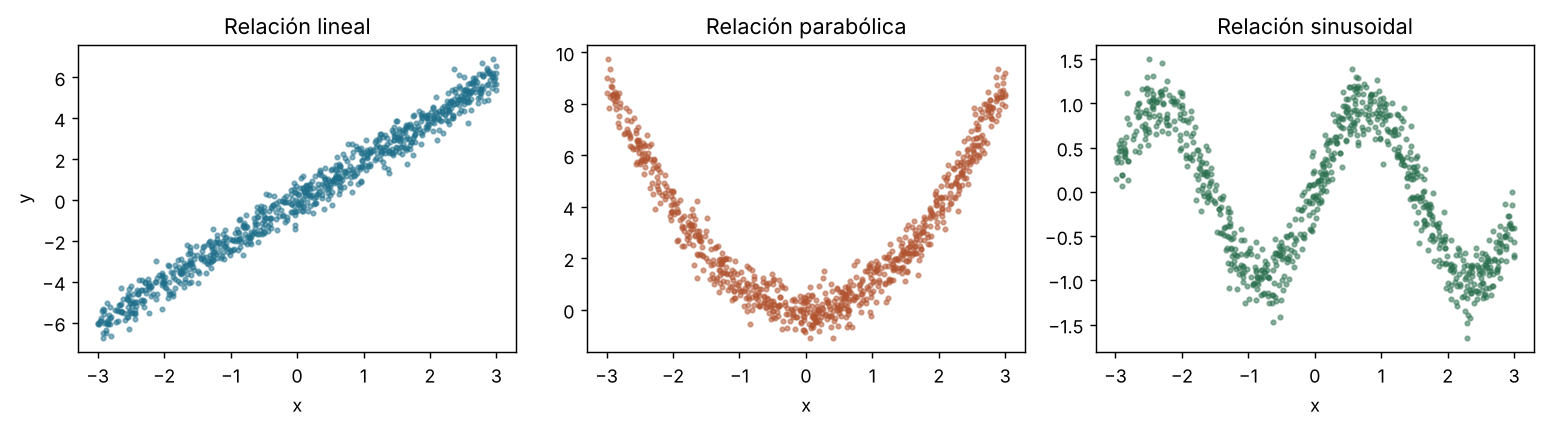

In [24]:
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
import matplotlib.pyplot as plt

print(f"{'relación':<12}{'Pearson':>10}{'Spearman':>10}{'Inf. mutua':>12}")
for nombre, y in relaciones.items():
    r = stats.pearsonr(x, y).statistic
    rho = stats.spearmanr(x, y).statistic
    im = mutual_info_regression(x.reshape(-1, 1), y, random_state=2026)[0]
    print(f"{nombre:<12}{r:>10.3f}{rho:>10.3f}{im:>12.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (nombre, y), color in zip(axes, relaciones.items(), ["#1f6f8b", "#b1532f", "#2a6f4e"]):
    ax.scatter(x, y, s=6, alpha=0.5, color=color)
    ax.set_title(f"Relación {nombre}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

**Comentario.** En la relación lineal los tres indicadores son altos. En la parabólica, Pearson y Spearman caen cerca de cero porque **no hay relación lineal ni monótona**: la mitad izquierda baja y la derecha sube, y las dos tendencias se compensan. En la sinusoidal dan un valor moderado (-0,39) que engaña en los dos sentidos: no refleja la intensidad de la dependencia, que es muy fuerte, sino un detalle de la ventana elegida, como se analiza en el ejercicio propuesto 2. En ambos casos la **información mutua sigue siendo alta** (1,47 y 1,18 nats). La información mutua mide cuánta incertidumbre sobre $y$ se reduce al conocer $x$, **sin presuponer forma funcional alguna**, y vale cero solo si las variables son independientes. Se expresa en *nats* (logaritmo natural) y no está acotada en $[0, 1]$, de modo que sirve para ordenar variables, no para leerla como un coeficiente de correlación.

### Ejercicio 13. Correlaciones espurias y comparaciones múltiples

Generar 60 variables completamente aleatorias e independientes con 40 observaciones cada una. **Calcular las correlaciones de todas las parejas y contar cuántas resultan "significativas" al nivel 0,05 por puro azar.** Aplicar después la [corrección de Bonferroni](https://es.wikipedia.org/wiki/Correcci%C3%B3n_de_Bonferroni), propuesta por el matemático [Carlo Emilio Bonferroni](https://es.wikipedia.org/wiki/Carlo_Emilio_Bonferroni), y comprobar cómo cambia el recuento. **Reflexionar sobre las correlaciones espurias.**

**Ayuda:** [`itertools.combinations`](https://docs.python.org/es/3/library/itertools.html#itertools.combinations), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y, como ampliación, [`scipy.stats.false_discovery_control`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html). Repaso en el apartado 8.

**Datos de partida.**

In [25]:
import numpy as np

rng = np.random.default_rng(2026)
n_vars, n_obs = 60, 40
datos = rng.normal(size=(n_obs, n_vars))   # 60 columnas independientes entre sí
alfa = 0.05                                # nivel de significación

#### Solución del ejercicio 13

In [26]:
from itertools import combinations
from scipy import stats

p_valores = np.array([stats.pearsonr(datos[:, i], datos[:, j]).pvalue
                      for i, j in combinations(range(n_vars), 2)])

n_parejas = len(p_valores)
sig_sin_correccion = (p_valores < alfa).sum()
alfa_bonferroni = alfa / n_parejas
sig_bonferroni = (p_valores < alfa_bonferroni).sum()

print(f"Parejas analizadas: {n_parejas}")
print(f"Significativas al 0,05 sin corrección: {sig_sin_correccion} "
      f"(esperadas por azar: {alfa * n_parejas:.1f})")
print(f"Umbral de Bonferroni: {alfa_bonferroni:.2e}")
print(f"Significativas tras Bonferroni: {sig_bonferroni}")

# Ampliación: control de la tasa de falsos descubrimientos (Benjamini-Hochberg)
p_ajustados = stats.false_discovery_control(p_valores)
print(f"Significativas con Benjamini-Hochberg: {(p_ajustados < alfa).sum()}")

Parejas analizadas: 1770
Significativas al 0,05 sin corrección: 103 (esperadas por azar: 88.5)
Umbral de Bonferroni: 2.82e-05
Significativas tras Bonferroni: 0
Significativas con Benjamini-Hochberg: 0


**Comentario.** Aunque todas las variables son independientes, **103 de las 1770 parejas (un 5,8 %) salen "significativas"**, cerca de las 88,5 que cabe esperar por azar, simplemente porque se realizan muchos contrastes: es exactamente lo que significa un nivel de significación de 0,05. La **corrección de Bonferroni** divide el nivel de significación entre el número de comparaciones y elimina todos los falsos hallazgos, a costa de ser muy exigente cuando sí hay relaciones reales. El procedimiento de Benjamini y Hochberg es una alternativa menos conservadora, que controla la proporción de falsos descubrimientos; aquí también deja cero parejas, como corresponde a unos datos sin ninguna relación.

Es el mecanismo que genera las correlaciones absurdas recopiladas en webs como [Spurious Correlations](https://www.tylervigen.com/spurious-correlations): **rastrear miles de series hasta encontrar parejas que casan por casualidad**. En la exploración de un conjunto de datos con muchas variables, una matriz de correlaciones grande contendrá siempre algunas relaciones llamativas que no significan nada.

### Ejercicio 14. Variable de confusión y correlación parcial

**Simular el ejemplo clásico de la [variable de confusión](https://es.wikipedia.org/wiki/Variable_de_confusi%C3%B3n)**: una variable $Z$ (la temperatura) que influye sobre otras dos, $X$ (consumo de helados) e $Y$ (número de bañistas). $X$ e $Y$ aparecerán fuertemente correlacionadas sin relación causal directa. **Implementar la [correlación parcial](https://es.wikipedia.org/wiki/Correlaci%C3%B3n_parcial) de $X$ e $Y$ controlando $Z$** y comprobar que la correlación aparente se desvanece.

La correlación parcial se calcula a partir de las tres correlaciones simples:

$$r_{XY \cdot Z} = \frac{r_{XY} - r_{XZ}\, r_{YZ}}{\sqrt{(1 - r_{XZ}^2)(1 - r_{YZ}^2)}}$$

**Ayuda:** [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y, para comprobar el resultado por otra vía, [`np.polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html) y [`np.polyval`](https://numpy.org/doc/stable/reference/generated/numpy.polyval.html). Repaso en el apartado 8.

**Datos de partida.** Trescientos días con temperaturas entre 10 y 40 grados. Los helados y los bañistas dependen solo de la temperatura, cada uno con su propio ruido.

In [27]:
import numpy as np

rng = np.random.default_rng(2026)
n = 300
temperatura = rng.uniform(10, 40, n)                # Z: variable de confusión
helados = 2 * temperatura + rng.normal(0, 5, n)     # X depende de Z
banhistas = 3 * temperatura + rng.normal(0, 8, n)   # Y depende de Z

#### Solución del ejercicio 14

In [28]:
from scipy import stats

def correlacion_parcial(x, y, z):
    """Correlación de x e y eliminando el efecto lineal de z."""
    r_xy = stats.pearsonr(x, y).statistic
    r_xz = stats.pearsonr(x, z).statistic
    r_yz = stats.pearsonr(y, z).statistic
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))


def residuos(v, z):
    """Parte de v que no explica una recta en función de z."""
    return v - np.polyval(np.polyfit(z, v, 1), z)


r_aparente = stats.pearsonr(helados, banhistas).statistic
r_parcial = correlacion_parcial(helados, banhistas, temperatura)
r_residuos = stats.pearsonr(residuos(helados, temperatura),
                            residuos(banhistas, temperatura)).statistic

print(f"Correlación aparente helados-bañistas:          {r_aparente:.3f}")
print(f"Correlación parcial controlando la temperatura: {r_parcial:.3f}")
print(f"Correlación entre los residuos (comprobación):  {r_residuos:.3f}")

Correlación aparente helados-bañistas:          0.905
Correlación parcial controlando la temperatura: -0.071
Correlación entre los residuos (comprobación):  -0.071


**Comentario.** La correlación aparente entre helados y bañistas es alta, pero **al controlar la temperatura la correlación parcial cae cerca de cero**: la relación estaba enteramente explicada por la variable de confusión. La comprobación por residuos muestra qué significa "controlar": se quita a cada variable lo que explica la temperatura y se correlaciona lo que queda, con el mismo resultado que la fórmula.

Este es el fundamento de por qué **correlación no implica causalidad**, y de por qué un modelo predictivo que funciona no autoriza afirmaciones del tipo "si cambia $X$, cambiará $Y$": prohibir los helados no vaciaría las playas.

### Ejercicio 15. Pearson desde cero e intervalo de confianza por bootstrap

**Implementar el coeficiente de Pearson a partir de su definición** (sin usar funciones de correlación ya hechas) y **validarlo contra SciPy**. A continuación, **estimar un intervalo de confianza del 95 % para el coeficiente mediante remuestreo [bootstrap](https://es.wikipedia.org/wiki/Bootstrapping_(estad%C3%ADstica))**, el método propuesto por [Bradley Efron](https://es.wikipedia.org/wiki/Bradley_Efron) en 1979, sin recurrir a hipótesis sobre la distribución de los datos.

**Ayuda:** [`Generator.integers`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html) para elegir índices con reemplazo, [`np.percentile`](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html) y, para comparar, el método `confidence_interval` del resultado de [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html). Repaso de la fórmula en el apartado 4.

**Datos de partida.** Ciento veinte puntos de una relación lineal con ruido. El remuestreo usa un generador propio, con la misma semilla, para que su resultado no dependa de cuántas veces se hayan ejecutado las celdas anteriores.

In [29]:
import numpy as np

rng = np.random.default_rng(2026)
x = rng.uniform(0, 10, 120)
y = 1.5 * x + rng.normal(0, 3, 120)

n_repeticiones = 5000          # remuestras del bootstrap
nivel = 0.95                   # nivel de confianza

#### Solución del ejercicio 15

In [30]:
from scipy import stats

def pearson_desde_cero(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    dx = x - x.mean()
    dy = y - y.mean()
    return (dx * dy).sum() / np.sqrt((dx**2).sum() * (dy**2).sum())


r_propio = pearson_desde_cero(x, y)
resultado_scipy = stats.pearsonr(x, y)
print(f"Pearson propio: {r_propio:.6f}")
print(f"Pearson SciPy:  {resultado_scipy.statistic:.6f}")
print(f"Diferencia:     {abs(r_propio - resultado_scipy.statistic):.2e}")

# Intervalo de confianza por bootstrap
rng_boot = np.random.default_rng(2026)
n = x.size
estimaciones = np.empty(n_repeticiones)
for k in range(n_repeticiones):
    indices = rng_boot.integers(0, n, n)        # muestreo con reemplazo
    estimaciones[k] = pearson_desde_cero(x[indices], y[indices])

cola = 100 * (1 - nivel) / 2
ic_bajo, ic_alto = np.percentile(estimaciones, [cola, 100 - cola])
ic_fisher = resultado_scipy.confidence_interval(confidence_level=nivel)
print(f"\nr estimado: {r_propio:.3f}")
print(f"IC 95 % por bootstrap:       [{ic_bajo:.3f}, {ic_alto:.3f}]")
print(f"IC 95 % con Fisher (SciPy): [{ic_fisher.low:.3f}, {ic_fisher.high:.3f}]")

Pearson propio: 0.784633
Pearson SciPy:  0.784633
Diferencia:     1.11e-16



r estimado: 0.785
IC 95 % por bootstrap:       [0.712, 0.842]
IC 95 % con Fisher (SciPy): [0.704, 0.845]


**Comentario.** La implementación manual coincide con SciPy hasta la precisión de la máquina, lo que confirma que **el coeficiente no es más que la covarianza normalizada por las desviaciones típicas**. El **bootstrap** remuestrea los datos con reemplazo miles de veces y usa los percentiles de las estimaciones como intervalo de confianza, un método que **no exige suponer normalidad** y resulta muy útil cuando la muestra es pequeña o de distribución desconocida. El intervalo que da SciPy se basa en la transformación de Fisher, que sí supone normalidad; aquí los dos intervalos son muy parecidos, como cabe esperar con datos generados con ruido gaussiano.

## Para cerrar

Buen trabajo si habéis llegado hasta el final, y más aún si os habéis peleado con los del nivel avanzado. Para seguir practicando tenéis los ejercicios con datos reales (`datos-reales-ud1.ipynb`) y los propuestos del final de los apuntes. Si os ha quedado alguna duda, traedla a la tutoría colectiva o al foro: para eso están.

_Pepe Calo_